<a href="https://colab.research.google.com/github/nsgilbert23/titanic_notebook/blob/main/Titanic_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Import the libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn

print("pandas :", pd.__version__)
print("seaborn:", sns.__version__)
print("sklearn:", sklearn.__version__)

pandas : 2.2.3
seaborn: 0.13.2
sklearn: 1.6.1


### step2 : Load the dataset

In [7]:
df = pd.read_csv("titanic.csv")
print(df.shape)
df.head(3)

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True


In [8]:
df.tail(3)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


### step3: Check column types and gaps with info()

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


###Step 4: Select variables (columns) and rows

In [10]:
ages = df["age"]                      # one column  -> Series
small = df[["sex", "age", "fare"]]    # many columns -> DataFrame
print(small.head(3))

print(df.loc[0, "age"])            # row label 0, column "age“ (selects by row and column labels.)
print(df.iloc[0:2, 0:4])              # rows 0-1, columns 0-3 (selects by integer position.)

      sex   age     fare
0    male  22.0   7.2500
1  female  38.0  71.2833
2  female  26.0   7.9250
22.0
   survived  pclass     sex   age
0         0       3    male  22.0
1         1       1  female  38.0


### step4: Filter rows with conditions

In [15]:
adults = df[df["age"] >= 18]
women_first = df[(df["sex"] == "female") & (df["class"] == "First")]

print("adult people 18 years old and above :", len(adults))
print("number of women in first class :", len(women_first))

rich = df.query("fare > 100")         # same idea, written as text
print(rich.shape)


adult people 18 years old and above : 601
number of women in first class : 94
(53, 15)


### Step 5: Clean: duplicates and repeated *columns*

In [16]:
print(df.duplicated().sum())    # rows that look identical

# These are different passengers who share the same values
# (the dataset has no name/ID column), so we KEEP them.

# Remove columns that repeat information we already have
df = df.drop(columns=["alive", "embark_town", "who", "adult_male"])
print(df.shape)
print(df.columns.tolist())


107
(891, 11)
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'deck', 'alone']


### Step 6: Manipulate: new columns and sorting

In [17]:
df["family_size"] = df["sibsp"] + df["parch"] + 1
df["fare_per_person"] = df["fare"] / df["family_size"]

top = df.sort_values("fare", ascending=False)
print(top[["class", "fare", "family_size"]].head(3))


     class      fare  family_size
679  First  512.3292            2
258  First  512.3292            1
737  First  512.3292            1


### Step 7: Convert variables to the right type

In [18]:
df["sex_code"] = df["sex"].map({"male": 0, "female": 1})
df["class"] = df["class"].astype("category")
print(df[["sex", "sex_code", "class"]].dtypes)

# Text that should be numbers -> numbers (bad values become NaN)
s = pd.Series(["10", "20", "abc"])
print(pd.to_numeric(s, errors="coerce").tolist())


sex           object
sex_code       int64
class       category
dtype: object
[10.0, 20.0, nan]


### Step 8: Combine data frames: merge (join columns)

In [19]:
ports = pd.DataFrame({
    "embarked":  ["S", "C", "Q"],
    "port_name": ["Southampton", "Cherbourg", "Queenstown"]})

merged = df.merge(ports, on="embarked", how="left")
print(merged[["embarked", "port_name"]].head(3))


  embarked    port_name
0        S  Southampton
1        C    Cherbourg
2        S  Southampton


### Step 9: Combine data frames: concat (stack)

In [20]:
part1 = df.iloc[0:5]       # rows 0-4
part2 = df.iloc[5:10]      # rows 5-9

both = pd.concat([part1, part2])    # stack rows
print(both.shape)

extra = pd.DataFrame({"checked": [True] * 10})
side = pd.concat([both.reset_index(drop=True), extra], axis=1)
print(side.shape)                   # one more column


(10, 14)
(10, 15)


### Step 10: Group and summarise

In [21]:
print(df.groupby("sex")["survived"].mean().round(2))

print(df.groupby("class", observed=True)["fare"]
        .agg(["mean", "median", "count"]).round(1))


sex
female    0.74
male      0.19
Name: survived, dtype: float64
        mean  median  count
class                      
First   84.2    60.3    216
Second  20.7    14.2    184
Third   13.7     8.0    491


### Step 11: Descriptive statistics with describe()

In [22]:
print(df[["age", "fare"]].describe().round(1))


         age   fare
count  714.0  891.0
mean    29.7   32.2
std     14.5   49.7
min      0.4    0.0
25%     20.1    7.9
50%     28.0   14.5
75%     38.0   31.0
max     80.0  512.3


### Step 12: Centre of the data: mean, median, mode

In [23]:
print("Mean age  :", round(df["age"].mean(), 1))
print("Median age:", df["age"].median())
print("Mode port :", df["embarked"].mode()[0])

print(df["class"].value_counts())


Mean age  : 29.7
Median age: 28.0
Mode port : S
class
Third     491
First     216
Second    184
Name: count, dtype: int64


### Step 13: Statistics with SciPy: skewness and correlation

In [24]:
print("Skewness of fare:", round(stats.skew(df["fare"]), 2))

both = df[["age", "fare"]].dropna()
r, p = stats.pearsonr(both["age"], both["fare"])
print("Correlation age-fare:", round(r, 2), " p-value:", round(p, 3))


Skewness of fare: 4.78
Correlation age-fare: 0.1  p-value: 0.01


### Step 14: Correlation table

In [25]:
cols = ["survived", "pclass", "age", "fare", "family_size"]
print(df[cols].corr().round(2))


             survived  pclass   age  fare  family_size
survived         1.00   -0.34 -0.08  0.26         0.02
pclass          -0.34    1.00 -0.37 -0.55         0.07
age             -0.08   -0.37  1.00  0.10        -0.30
fare             0.26   -0.55  0.10  1.00         0.22
family_size      0.02    0.07 -0.30  0.22         1.00


### Step 15: Basic visualisation with Matplotlib

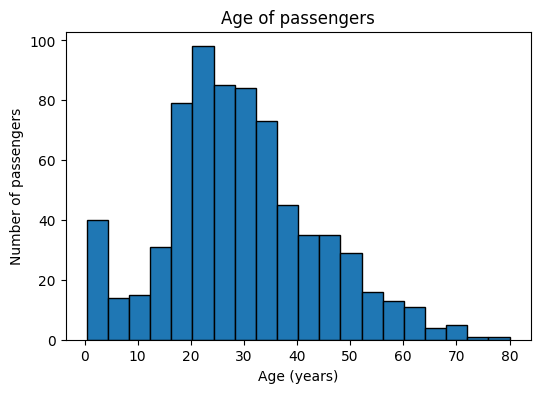

In [26]:
plt.figure(figsize=(6, 4))
plt.hist(df["age"].dropna(), bins=20, edgecolor="black")
plt.title("Age of passengers")
plt.xlabel("Age (years)")
plt.ylabel("Number of passengers")
plt.show()


### Step 16: Seaborn: count plot and box plot

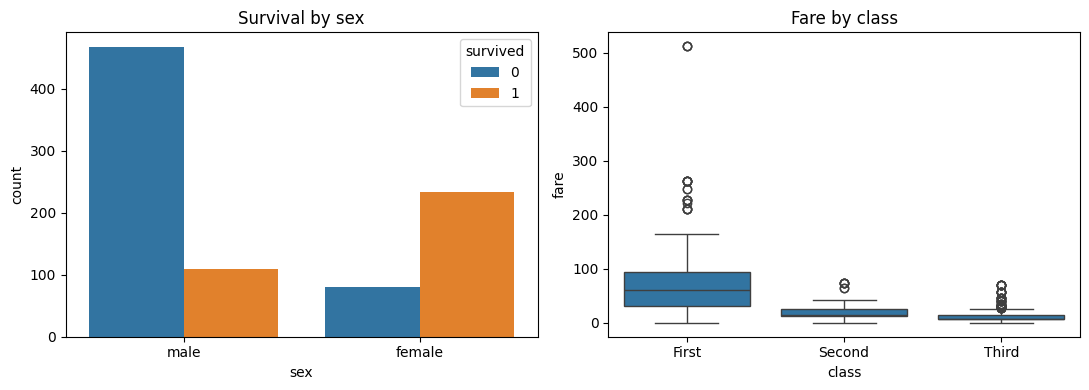

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df, x="sex", hue="survived", ax=axes[0])
axes[0].set_title("Survival by sex")

sns.boxplot(data=df, x="class", y="fare", ax=axes[1])
axes[1].set_title("Fare by class")

plt.tight_layout()
plt.show()


### Step 17: Seaborn: line, regression, histogram, density

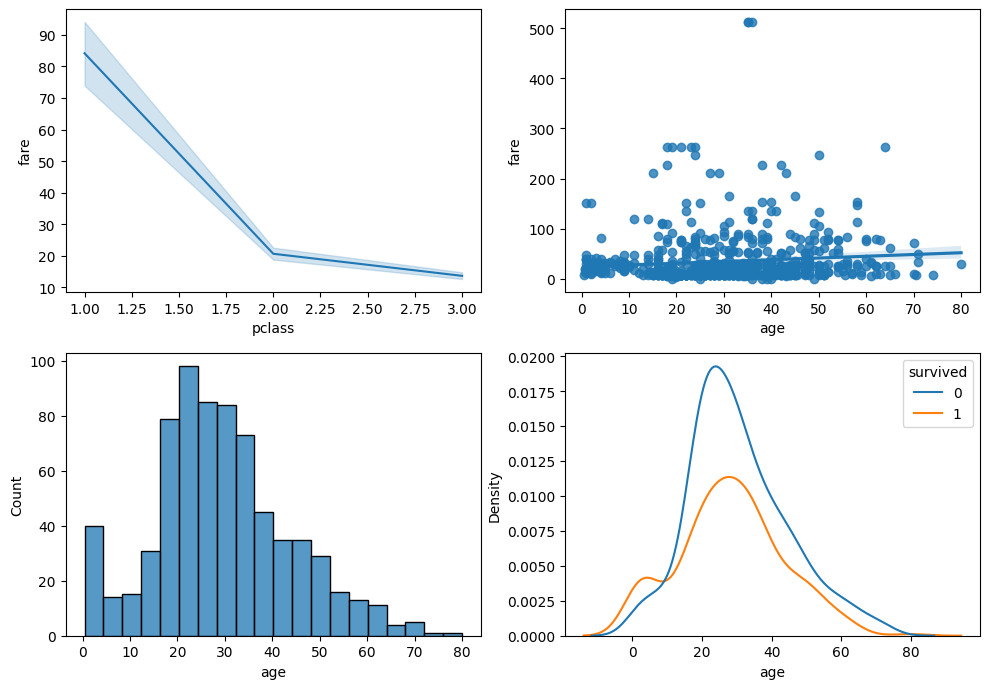

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

sns.lineplot(data=df, x="pclass", y="fare", ax=axes[0, 0])
sns.regplot(data=df, x="age", y="fare", ax=axes[0, 1])
sns.histplot(data=df, x="age", bins=20, ax=axes[1, 0])
sns.kdeplot(data=df, x="age", hue="survived", ax=axes[1, 1])

plt.tight_layout()
plt.show()


### Step 18: Seaborn: correlation heatmap

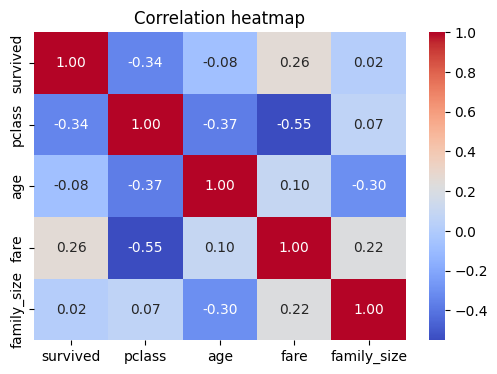

In [29]:
cols = ["survived", "pclass", "age", "fare", "family_size"]

plt.figure(figsize=(6, 4))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()


### Step 19: Pandas for bigger files: chunks and memory

In [30]:
url = ("https://raw.githubusercontent.com/"
       "mwaskom/seaborn-data/master/titanic.csv")
total_survivors = 0
for chunk in pd.read_csv(url, chunksize=200):    # 200 rows at a time
    total_survivors += chunk["survived"].sum()
print("Survivors:", total_survivors)

before = df.memory_usage(deep=True).sum() / 1024
df["sex"] = df["sex"].astype("category")         # smaller type
after = df.memory_usage(deep=True).sum() / 1024
print(round(before, 1), "KB ->", round(after, 1), "KB")


Survivors: 342
186.4 KB -> 140.7 KB


### Step 20: PySpark: start a session and load data

In [31]:
# !pip install pyspark      (needs Java; already available in Colab)
pd.read_csv(url).to_csv("titanic.csv", index=False)  # save a local copy

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder.appName("Titanic").getOrCreate()
sdf = spark.read.csv("titanic.csv", header=True, inferSchema=True)

print(sdf.count())
sdf.select("survived", "pclass", "sex", "age", "fare").show(5)


891
+--------+------+------+----+-------+
|survived|pclass|   sex| age|   fare|
+--------+------+------+----+-------+
|       0|     3|  male|22.0|   7.25|
|       1|     1|female|38.0|71.2833|
|       1|     3|female|26.0|  7.925|
|       1|     1|female|35.0|   53.1|
|       0|     3|  male|35.0|   8.05|
+--------+------+------+----+-------+
only showing top 5 rows


### Step 21: PySpark: group, fill gaps and filter

In [32]:
(sdf.groupBy("class")
    .agg(F.count("*").alias("passengers"),
         F.round(F.avg("fare"), 1).alias("avg_fare"))
    .show())

mean_age = sdf.select(F.mean("age")).first()[0]
sdf_clean = sdf.na.fill({"age": mean_age, "embarked": "S"})
print(sdf_clean.filter(F.col("age").isNull()).count())    # 0


+------+----------+--------+
| class|passengers|avg_fare|
+------+----------+--------+
| First|       216|    84.2|
|Second|       184|    20.7|
| Third|       491|    13.7|
+------+----------+--------+

0


### Step 22: PySpark: a preprocessing pipeline

In [33]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, VectorAssembler

imputer = Imputer(inputCols=["age", "fare"],
                  outputCols=["age_i", "fare_i"], strategy="median")
indexer = StringIndexer(inputCol="sex", outputCol="sex_i")
assembler = VectorAssembler(inputCols=["pclass", "sex_i", "age_i", "fare_i"],
                            outputCol="features")

pipe = Pipeline(stages=[imputer, indexer, assembler])
out = pipe.fit(sdf).transform(sdf)
out.select("features", "survived").show(3, truncate=False)
spark.stop()


+----------------------+--------+
|features              |survived|
+----------------------+--------+
|[3.0,0.0,22.0,7.25]   |0       |
|[1.0,1.0,38.0,71.2833]|1       |
|[3.0,1.0,26.0,7.925]  |1       |
+----------------------+--------+
only showing top 3 rows


### Step 23: Find missing values

In [34]:
missing = df.isnull().sum()
percent = (missing / len(df) * 100).round(1)

report = pd.DataFrame({"missing": missing, "percent": percent})
print(report[report["missing"] > 0])

print("Rows left if we drop every row with a gap:", len(df.dropna()))


          missing  percent
age           177     19.9
embarked        2      0.2
deck          688     77.2
Rows left if we drop every row with a gap: 182


### Step 24: Handle missing values with Pandas

In [35]:
df = df.drop(columns=["deck"])                     # 77% missing

df["age"] = df["age"].fillna(df["age"].median())    # number -> median
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])  # mode

print(df.isnull().sum().sum())    # total gaps left


0


### Step 25: Handle missing values with scikit-learn

In [36]:
url = ("https://raw.githubusercontent.com/"
       "mwaskom/seaborn-data/master/titanic.csv")
raw = pd.read_csv(url)

from sklearn.impute import SimpleImputer
num_imp = SimpleImputer(strategy="median")
cat_imp = SimpleImputer(strategy="most_frequent")

raw[["age"]] = num_imp.fit_transform(raw[["age"]])
raw[["embarked"]] = cat_imp.fit_transform(raw[["embarked"]])
print(raw[["age", "embarked"]].isnull().sum())


age         0
embarked    0
dtype: int64


## Outliers: values far from the rest

### Step 26: Detect outliers with the IQR rule

Limits: -26.72 to 65.63
Outliers: 116


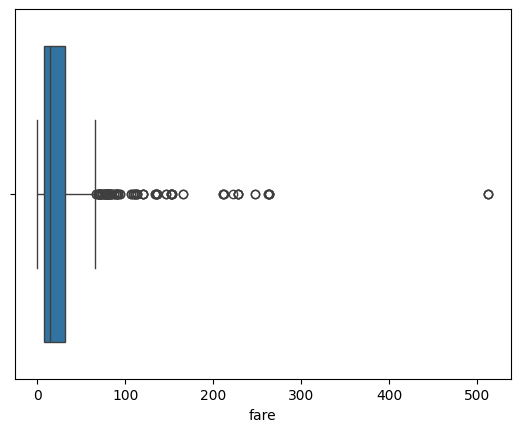

In [37]:
q1 = df["fare"].quantile(0.25)
q3 = df["fare"].quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outliers = df[(df["fare"] < low) | (df["fare"] > high)]
print("Limits:", round(low, 2), "to", round(high, 2))
print("Outliers:", len(outliers))

sns.boxplot(x=df["fare"])
plt.show()


### Step 27: Handle outliers: capping and log transform

In [38]:
df["fare_capped"] = df["fare"].clip(lower=low, upper=high)   # capping
df["fare_log"] = np.log1p(df["fare"])                         # log(1 + x)

print("Skew original:", round(stats.skew(df["fare"]), 2))
print("Skew capped  :", round(stats.skew(df["fare_capped"]), 2))
print("Skew log     :", round(stats.skew(df["fare_log"]), 2))

z = np.abs(stats.zscore(df["fare"]))          # alternative: z-score
print("Rows with |z| > 3:", (z > 3).sum())


Skew original: 4.78
Skew capped  : 1.08
Skew log     : 0.39
Rows with |z| > 3: 20


## Imbalanced datasets: the accuracy trap

## Step 28: Check the class balance

survived
0    549
1    342
Name: count, dtype: int64
survived
0    0.62
1    0.38
Name: proportion, dtype: float64


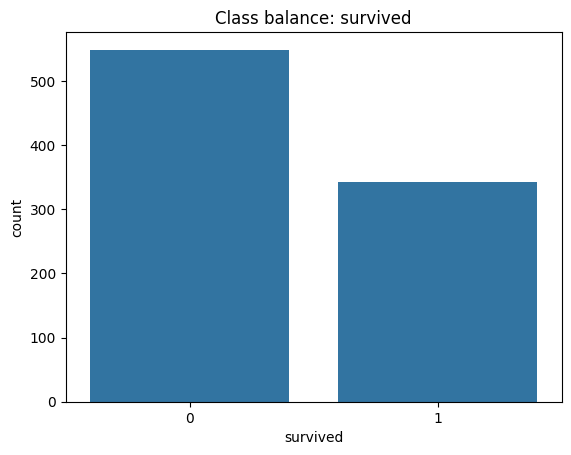

In [39]:
print(df["survived"].value_counts())
print(df["survived"].value_counts(normalize=True).round(2))

sns.countplot(data=df, x="survived")
plt.title("Class balance: survived")
plt.show()


### Step 29: Fix imbalance: random oversampling

In [40]:
from sklearn.utils import resample

majority = df[df["survived"] == 0]
minority = df[df["survived"] == 1]

minority_up = resample(minority, replace=True,
                       n_samples=len(majority), random_state=42)
balanced = pd.concat([majority, minority_up])

print(balanced["survived"].value_counts())


survived
0    549
1    549
Name: count, dtype: int64


### Step 30: Fix imbalance: SMOTE (imbalanced-learn)

In [41]:
# !pip install imbalanced-learn
from imblearn.over_sampling import SMOTE

X = df[["pclass", "sex_code", "age", "fare", "family_size"]]
y = df["survived"]

X_res, y_res = SMOTE(random_state=42).fit_resample(X, y)
print(y_res.value_counts())

# Option without resampling: give the small class more weight
# LogisticRegression(class_weight="balanced")


survived
0    549
1    549
Name: count, dtype: int64


## Data pipelines: why chain the steps?

A pipeline runs the same preprocessing steps, in the same order, on training data, test data and new data
It learns fill values and scales from the training data only, which prevents data leakage
One object holds everything: easy to reuse, share and deploy


### Step 31: Split into training and test sets

In [42]:
url = ("https://raw.githubusercontent.com/"
       "mwaskom/seaborn-data/master/titanic.csv")
raw = pd.read_csv(url)                      # start again from raw data

features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = raw[features]
y = raw["survived"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)


(712, 7) (179, 7)


###Step 32: Build the preprocessing steps

In [43]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ["age", "sibsp", "parch", "fare"]
cat_cols = ["pclass", "sex", "embarked"]

num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])


### Step 33: Combine, add a model and train

In [44]:
from sklearn.linear_model import LogisticRegression

prep = ColumnTransformer([("num", num_pipe, num_cols),
                          ("cat", cat_pipe, cat_cols)])

model = Pipeline([("prep", prep),
                  ("clf", LogisticRegression(max_iter=1000))])

model.fit(X_train, y_train)          # learns ONLY from training data
print("Test accuracy:", round(model.score(X_test, y_test), 3))


Test accuracy: 0.804


### Step 34: Use the pipeline on a new passenger

In [45]:
new = pd.DataFrame([{"pclass": 3, "sex": "female", "age": 22,
                     "sibsp": 0, "parch": 0, "fare": 8.05,
                     "embarked": "S"}])

print("Prediction :", model.predict(new)[0])          # 1 = survived
print("Probability:", model.predict_proba(new).round(2))


Prediction : 1
Probability: [[0.37 0.63]]


### Step 35: Save the cleaned data

In [46]:
df.to_csv("titanic_clean.csv", index=False)
print(pd.read_csv("titanic_clean.csv").shape)

# Google Colab only: download the file to your computer
# from google.colab import files
# files.download("titanic_clean.csv")


(891, 15)
